# 01. 当初案：metadata encoder の空間と生成 ΔW の空間

柱 B の当初案（[research_overview.md](../../docs/meetings/20261016/research_overview.md)）を、CheXpert race-known の
1 段・ERM の Spatial LoRA（seed 42・43・44）で確かめる。

- 空間：metadata encoder の出力 c（16 次元）と、c から生成した ΔW（stage3・stage4・fc と、その全部）。
  どちらも属性だけの関数なので、同じ属性の組み合わせ（セル、3,599 通り）の行は同じ点に写る。
- 群の作り方：k-means（K = 2〜8）。val の行に当て、test の行に同じ中心を当てる。
- 物差し：しきい値 0.5 の FPR（所見のある画像を「所見なし」と出す見落とし）。群は val で作り、test で測る。

見ること：

1. 空間が属性のどれで決まっているか（推論 1：見つかる群は属性の組み合わせを束ね直したもの）
2. クラスタの差は性能の差か、陽性率の差か（推論 2：ERM の距離は「予測の仕方の違い」を表す）
3. クラスタの FPR の違いは、属性・病種・デバイスや術後の所見の構成で説明できるか
4. seed をまたいで同じクラスタになるか

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rootutils
from IPython.display import display
from sklearn.linear_model import LinearRegression

ROOT = rootutils.setup_root(Path.cwd(), indicator=".project-root", pythonpath=True)
from analysis.common.paths import STYLE_SHEET, study_dir  # noqa: E402
from analysis.latent_subgroup_spaces import subgroups as sg  # noqa: E402

plt.style.use(STYLE_SHEET)
PACKAGE = study_dir("latent_subgroup_spaces")
TOPIC = "01_initial_spaces"
RESULTS = PACKAGE / "results" / TOPIC
FIGURES = PACKAGE / "figures" / TOPIC
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

RUNS = {
    42: "20261002T125005Z-spatial-lora-chexpert-race-known-s42-a21c",
    43: "20261002T145233Z-spatial-lora-chexpert-race-known-s43-424e",
    44: "20261002T165551Z-spatial-lora-chexpert-race-known-s44-eb13",
}
KS = [2, 3, 4, 6, 8]
# 群の中身を読むときの K。8 群（評価の基準）と同じ粒度に近く、各クラスタの陰性が数千ある大きさ。
K_READ = 4
ATTRIBUTES = ["age65", "sex", "race_group", "ethnicity", "frontal_lateral", "ap_pa"]
DISEASE_COLUMNS = [f"dz_{name}" for name in sg.DISEASES]
CONTEXT_COLUMNS = list(sg.CONTEXT_FLAGS)

## 読み込み

val・test の行ごとの c と、セルごとの ΔW の Gram。ΔW は Gram から重み付き kernel PCA で座標にし（ΔW どうしの
距離を保つ）、行にはセル番号で座標を引く。`all` は 3 stage の Gram の和で、3 stage の ΔW を並べたベクトルの距離になる。

In [2]:
def delta_spaces(run_id, splits):
    cells, _, grams = sg.load_cells(run_id)
    grams["all"] = grams["stage3"] + grams["stage4"] + grams["fc"]
    weight = cells.train_count.to_numpy() + 1e-3
    spaces = {}
    for stage, gram in grams.items():
        coordinates = sg.kernel_coordinates(gram, weight)
        spaces[f"dW_{stage}"] = {split: coordinates[data.frame.cell.to_numpy()] for split, data in splits.items()}
    return spaces


DATA, SPACES = {}, {}
for seed, run_id in RUNS.items():
    splits = {split: sg.load_split(run_id, split) for split in ("val", "test")}
    DATA[seed] = splits
    SPACES[seed] = {"c": {split: data.condition for split, data in splits.items()}, **delta_spaces(run_id, splits)}

overall = pd.DataFrame(
    [
        {
            "seed": seed,
            "split": split,
            "n": len(data.frame),
            "prevalence": data.frame.target.mean(),
            "fpr": data.frame.pred[data.frame.target == 0].mean(),
            "tpr": data.frame.pred[data.frame.target == 1].mean(),
        }
        for seed, splits in DATA.items()
        for split, data in splits.items()
    ]
)
display(overall.round(3))
display(pd.DataFrame({space: [SPACES[42][space]["val"].shape[1]] for space in SPACES[42]}, index=["dims"]))

,seed,split,n,prevalence,fpr,tpr
0,42,val,20058,0.099,0.297,0.873
1,42,test,19617,0.104,0.304,0.870
2,43,val,20058,0.099,0.203,0.807
3,43,test,19617,0.104,0.207,0.798
4,44,val,20058,0.099,0.224,0.818
5,44,test,19617,0.104,0.229,0.823


,c,dW_stage3,dW_stage4,dW_fc,dW_all
dims,16,20,16,22,19


## 1. 空間は属性のどれで決まっているか

各空間の座標（val の行）を、属性 1 つずつの one-hot（年齢は連続値のまま 5 歳刻みの one-hot）に回帰し、
説明される分散の割合（R²）を出す。属性の組み合わせ全部（セル）で R² = 1 になるのは定義どおり。
どの属性が空間の形を決めているかを見る。

In [3]:
def attribute_r2(space, frame):
    columns = {"age (5y)": (frame.age // 5).astype(int), **{name: frame[name] for name in ATTRIBUTES}}
    rows = {}
    for name, values in columns.items():
        design = pd.get_dummies(values.astype(str)).to_numpy(dtype=float)
        rows[name] = LinearRegression().fit(design, space).score(design, space)
    return rows


r2 = pd.DataFrame(
    [
        {"seed": seed, "space": space, **attribute_r2(values["val"], DATA[seed]["val"].frame)}
        for seed, spaces in SPACES.items()
        for space, values in spaces.items()
    ]
)
r2_mean = r2.drop(columns="seed").groupby("space").mean()
r2.to_csv(RESULTS / "attribute_r2.csv", index=False)
display(r2_mean.round(3))

,age (5y),age65,sex,race_group,ethnicity,frontal_lateral,ap_pa
space,,,,,,,
c,0.355,0.235,0.083,0.177,0.093,0.101,0.090
dW_all,0.097,0.033,0.046,0.122,0.042,0.045,0.046
dW_fc,0.108,0.038,0.044,0.122,0.040,0.049,0.053
dW_stage3,0.090,0.030,0.043,0.116,0.039,0.041,0.042
dW_stage4,0.114,0.039,0.053,0.138,0.050,0.051,0.054


## 2. k-means のクラスタと、test の FPR

K ごと・空間ごと・seed ごとに、test のクラスタの最悪 FPR を、群の大きさを保って並べ替えた帰無分布と比べる。
`val_chosen_test_fpr` は val で最悪だったクラスタの test の FPR（勝者の呪いを除いた値）。
基準として、評価の 8 群（年齢 65 歳 × race）も同じ物差しで並べる。

In [4]:
PARTITIONS = {}
summary_rows = []
for seed, splits in DATA.items():
    val, test = splits["val"].frame, splits["test"].frame
    PARTITIONS[(seed, "attr8", 8)] = (val.attr8.to_numpy(), test.attr8.to_numpy())
    for space, values in SPACES[seed].items():
        for k in KS:
            PARTITIONS[(seed, space, k)] = sg.kmeans_groups(values["val"], values["test"], k)
    for (part_seed, space, k), (val_groups, test_groups) in PARTITIONS.items():
        if part_seed != seed:
            continue
        row = sg.summarize_partition(space, val_groups, test_groups, val, test)
        row.update(
            seed=seed,
            k=k,
            nmi_attr8=sg.explained_by(test_groups, test, ["age65", "race_group"]),
            nmi_age65=sg.explained_by(test_groups, test, ["age65"]),
            nmi_view=sg.explained_by(test_groups, test, ["frontal_lateral", "ap_pa"]),
        )
        summary_rows.append(row)

summary = pd.DataFrame(summary_rows)
summary.to_csv(RESULTS / "kmeans_summary.csv", index=False)
columns = ["worst_fpr", "null_worst_p95", "excess_over_null", "val_chosen_test_fpr", "fpr_sd", "prevalence_range", "nmi_attr8", "nmi_age65", "nmi_view"]
summary_mean = summary.groupby(["partition", "k"])[columns].mean()
display(summary_mean.round(3))

worst_fpr  null_worst_p95  excess_over_null  val_chosen_test_fpr  \
partition k                                                                     
attr8     8      0.363           0.284             0.099                0.322   
c         2      0.316           0.253             0.067                0.316   
          3      0.414           0.258             0.163                0.414   
          4      0.421           0.261             0.167                0.421   
          6      0.471           0.265             0.214                0.471   
          8      0.507           0.272             0.247                0.507   
dW_all    2      0.276           0.255             0.027                0.276   
          3      0.388           0.263             0.135                0.388   
          4      0.465           0.266             0.210                0.465   
          6      0.486           0.271             0.227                0.486   
          8      0.497           0.276             0.235                0.496   
dW_fc     2      0.365           0.256             0.116                0.365   
          3      0.408           0.264             0.155                0.408   
          4      0.477           0.271             0.221                0.477   
          6      0.519           0.281             0.257                0.519   
          8      0.522           0.290             0.255                0.517   
dW_stage3 2      0.278           0.255             0.029                0.278   
          3      0.423           0.258             0.172                0.423   
          4      0.438           0.264             0.183                0.438   
          6      0.501           0.272             0.242                0.501   
          8      0.498           0.277             0.236                0.498   
dW_stage4 2      0.277           0.255             0.028                0.277   
          3      0.287           0.265             0.034                0.287   
          4      0.421           0.267             0.166                0.421   
          6      0.448           0.272             0.188                0.448   
          8      0.496           0.279             0.233                0.496   

             fpr_sd  prevalence_range  nmi_attr8  nmi_age65  nmi_view  
partition k                                                            
attr8     8   0.074             0.114      1.000      0.578     0.004  
c         2   0.066             0.083      0.337      0.559     0.010  
          3   0.095             0.144      0.280      0.403     0.280  
          4   0.093             0.166      0.308      0.416     0.332  
          6   0.105             0.192      0.289      0.309     0.325  
          8   0.111             0.229      0.308      0.259     0.366  
dW_all    2   0.048             0.069      0.220      0.376     0.008  
          3   0.079             0.144      0.250      0.374     0.104  
          4   0.096             0.187      0.256      0.357     0.277  
          6   0.105             0.243      0.258      0.333     0.292  
          8   0.112             0.270      0.259      0.312     0.290  
dW_fc     2   0.066             0.107      0.133      0.175     0.182  
          3   0.073             0.155      0.208      0.283     0.200  
          4   0.088             0.202      0.205      0.247     0.322  
          6   0.101             0.258      0.245      0.285     0.323  
          8   0.107             0.284      0.280      0.309     0.319  
dW_stage3 2   0.050             0.070      0.234      0.393     0.006  
          3   0.085             0.171      0.225      0.332     0.076  
          4   0.090             0.183      0.272      0.380     0.182  
          6   0.108             0.255      0.252      0.320     0.313  
          8   0.112             0.266      0.259      0.313     0.319  
dW_stage4 2   0.049             0.070      0.224      0.380     0.007  
          3   0.

## 3. クラスタの差は性能の差か、陽性率の差か

K = 4 のクラスタごとに、陽性率と FPR を並べる。ERM は陽性率の高い群で得点を全体に上げるので、陽性率が高い
クラスタほど陰性も「所見なし」と出やすく、FPR が上がる。FPR の違いがこの関係だけで決まっているなら、
クラスタは「不利に扱われている群」ではなく「基底率の違う群」を拾っている。

/tmp/ipykernel_2504171/3867255887.py:21: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


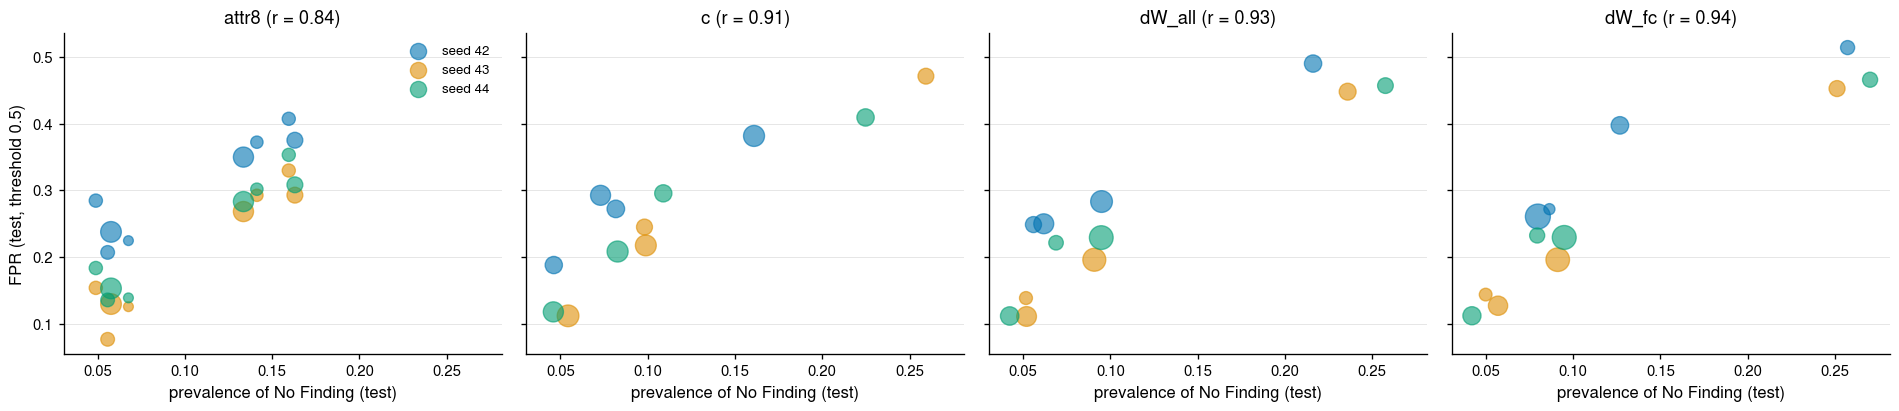

space
attr8        0.84
c            0.91
dW_all       0.93
dW_fc        0.94
dW_stage3    0.91
dW_stage4    0.93
Name: corr(prevalence, fpr), dtype: float64

In [5]:
tables = []
for (seed, space, k), (_, test_groups) in PARTITIONS.items():
    if k not in (K_READ, 8) or (space != "attr8" and k != K_READ):
        continue
    table = sg.group_table(test_groups, DATA[seed]["test"].frame)
    tables.append(table.assign(seed=seed, space=space))
group_tables = pd.concat(tables, ignore_index=True)
group_tables.to_csv(RESULTS / "group_tables_k4.csv", index=False)

spaces_to_plot = ["attr8", "c", "dW_all", "dW_fc"]
fig, axes = plt.subplots(1, len(spaces_to_plot), figsize=(4 * len(spaces_to_plot), 3.6), sharex=True, sharey=True)
for axis, space in zip(axes, spaces_to_plot):
    part = group_tables[group_tables.space == space]
    for seed, rows in part.groupby("seed"):
        axis.scatter(rows.prevalence, rows.fpr, s=np.sqrt(rows.n_neg) * 2, alpha=0.6, label=f"seed {seed}")
    corr = part[["prevalence", "fpr"]].corr().iloc[0, 1]
    axis.set_title(f"{space} (r = {corr:.2f})")
    axis.set_xlabel("prevalence of No Finding (test)")
axes[0].set_ylabel("FPR (test, threshold 0.5)")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "prevalence_vs_fpr.png", dpi=150)
plt.show()
correlation = group_tables.groupby("space")[["prevalence", "fpr"]].apply(lambda part: part.corr().iloc[0, 1])
display(correlation.rename("corr(prevalence, fpr)").round(2))

## 4. FPR の違いは、属性・病種・文脈の構成で説明できるか

クラスタごとの見落とし数の O/E を、層を変えて出す。E は「層ごとの全体の FPR」をクラスタの陰性に当てた期待値。

- `none`：層なし（O/E = クラスタの FPR / 全体の FPR）
- `attr8`：年齢 65 歳 × race
- `inputs`：モデル入力の属性（年齢 65 歳・性別・race・正面側面・AP/PA）
- `context`：病種のうち件数の多いもの（胸水・無気肺・肺の陰影・心拡大・浮腫）・デバイス・術後（胸骨切開）・レポート種別
- `inputs+context`：両方

O/E の陰性数で重み付けした SD を、層ごとに出す。層を入れて SD が 0 に近づけば、その層でクラスタの違いが説明できる。

In [6]:
MAIN_DISEASES = ["dz_Pleural Effusion", "dz_Atelectasis", "dz_Lung Opacity", "dz_Cardiomegaly", "dz_Edema"]
STRATA = {
    "none": [],
    "attr8": ["age65", "race_group"],
    "inputs": ["age65", "sex", "race_group", "frontal_lateral", "ap_pa"],
    "context": [*MAIN_DISEASES, "device", "sternotomy", "report_type"],
    "inputs+context": ["age65", "sex", "race_group", "frontal_lateral", "ap_pa", *MAIN_DISEASES, "device", "sternotomy", "report_type"],
}


def oe_spread(test_groups, frame, strata):
    if not strata:
        frame = frame.assign(_all=0)
        strata = ["_all"]
    table = sg.standardized_excess(test_groups, frame, strata)
    table = table[table.n_neg >= sg.MIN_CELL]
    return float(np.sqrt(np.average((table.o_e - 1) ** 2, weights=table.n_neg)))


oe_rows = []
for (seed, space, k), (_, test_groups) in PARTITIONS.items():
    if k not in (K_READ, 8) or (space != "attr8" and k != K_READ):
        continue
    frame = DATA[seed]["test"].frame
    oe_rows.append({"seed": seed, "space": space, **{name: oe_spread(test_groups, frame, s) for name, s in STRATA.items()}})
oe = pd.DataFrame(oe_rows)
oe.to_csv(RESULTS / "oe_spread_k4.csv", index=False)
display(oe.drop(columns="seed").groupby("space").mean().round(3))

,none,attr8,inputs,context,inputs+context
space,,,,,
attr8,0.311,0.000,0.000,0.244,0.000
c,0.398,0.279,0.054,0.232,0.030
dW_all,0.404,0.253,0.073,0.233,0.056
dW_fc,0.373,0.251,0.062,0.199,0.044
dW_stage3,0.375,0.213,0.084,0.235,0.059
dW_stage4,0.380,0.217,0.083,0.241,0.066


## 5. val で最悪だったクラスタの中身

K = 4 の各空間で、val の FPR が最悪のクラスタを選び、test の陰性での属性・病種・文脈の割合を、陰性全体と比べる
（比 > 1 がクラスタに多い要因）。seed 42 だけを示し、3 seed の比の平均を表に書く。

In [7]:
FACTOR_FRAME_COLUMNS = ["young", "female", "black", "asian", "lateral", "pa", "affirmed_normal", *CONTEXT_COLUMNS, *DISEASE_COLUMNS]


def with_factor_columns(frame):
    return frame.assign(
        young=frame.age65 == 0,
        female=frame.sex == 1,
        black=frame.race_group == 3,
        asian=frame.race_group == 2,
        lateral=frame.frontal_lateral == 1,
        pa=frame.ap_pa == 1,  # ap_pa = 1 は PA（外来の立位撮影）。側面像は ap_pa が欠損
        affirmed_normal=frame.report_type == "affirmed_normal",
    )


enrich_rows = []
for (seed, space, k), (val_groups, test_groups) in PARTITIONS.items():
    if k != K_READ and space != "attr8":
        continue
    val_table = sg.group_table(val_groups, DATA[seed]["val"].frame)
    chosen = val_table.loc[val_table.fpr.idxmax(), "group"]
    frame = with_factor_columns(DATA[seed]["test"].frame)
    table = sg.enrichment(test_groups == chosen, frame, FACTOR_FRAME_COLUMNS)
    enrich_rows.append(table.assign(seed=seed, space=space))
enrich = pd.concat(enrich_rows, ignore_index=True)
enrich.to_csv(RESULTS / "worst_cluster_enrichment.csv", index=False)
display(enrich.pivot_table(index="factor", columns="space", values="ratio", aggfunc="mean").round(2))

space,attr8,c,dW_all,dW_fc,dW_stage3,dW_stage4
factor,,,,,,
affirmed_normal,1.39,1.84,2.15,2.28,1.89,1.89
asian,16.44,1.44,2.02,2.92,1.84,1.83
black,0.00,1.53,1.52,1.28,1.54,1.47
central_line,1.01,0.89,0.73,0.74,0.90,0.85
device,0.95,0.87,0.75,0.75,0.89,0.84
dz_Atelectasis,0.86,0.87,0.83,0.78,0.85,0.91
dz_Cardiomegaly,1.74,0.79,0.83,0.89,0.82,0.84
dz_Consolidation,0.72,0.86,0.83,0.90,0.86,0.83
dz_Edema,1.10,0.54,0.41,0.42,0.51,0.56


## 6. seed をまたいで同じクラスタになるか

同じ空間・同じ K の test の群番号どうしの ARI（3 seed の組の平均）。属性の組み合わせが同じ行は同じ点に写るので、
ARI が高ければ「どの属性で束ねるか」が seed によらず決まっている。

In [8]:
ari_rows = []
for space in SPACES[42]:
    for k in KS:
        groups = {seed: PARTITIONS[(seed, space, k)][1] for seed in RUNS}
        ari_rows.append({"space": space, "k": k, "ari": sg.seed_agreement(groups)})
ari = pd.DataFrame(ari_rows)
ari.to_csv(RESULTS / "seed_ari.csv", index=False)
display(ari.pivot(index="space", columns="k", values="ari").round(2))

k,2,3,4,6,8
space,,,,,
c,0.54,0.49,0.38,0.38,0.45
dW_all,0.69,0.38,0.50,0.44,0.47
dW_fc,0.08,0.24,0.42,0.46,0.39
dW_stage3,0.69,0.51,0.40,0.43,0.43
dW_stage4,0.67,0.49,0.34,0.38,0.38


## 7. K = 4 のクラスタを属性で書き下す

seed 42 の c と ΔW（all）のクラスタごとに、属性の構成（年齢の中央値、65 歳以上・女性・race・側面・PA の割合）を出す。

In [9]:
def describe_clusters(test_groups, frame):
    frame = with_factor_columns(frame).assign(cluster=test_groups)
    table = frame.groupby("cluster").agg(
        n=("target", "size"),
        age_median=("age", "median"),
        old=("age65", "mean"),
        female=("female", "mean"),
        black=("black", "mean"),
        asian=("asian", "mean"),
        lateral=("lateral", "mean"),
        pa=("pa", "mean"),
        prevalence=("target", "mean"),
    )
    fpr = sg.group_table(test_groups, frame).set_index("group").fpr
    return table.assign(fpr=fpr)


for space in ["c", "dW_all"]:
    print(space)
    display(describe_clusters(PARTITIONS[(42, space, K_READ)][1], DATA[42]["test"].frame).round(3))

c


,n,age_median,old,female,black,asian,lateral,pa,prevalence,fpr
cluster,,,,,,,,,,
0,3399,55.0,0.130,0.000,0.070,0.000,0.000,0.000,0.082,0.272
1,7543,50.0,0.072,0.606,0.313,0.094,0.193,0.177,0.161,0.381
2,5627,75.0,0.870,0.628,0.134,0.090,0.259,0.233,0.073,0.292
3,3048,78.0,1.000,0.000,0.108,0.000,0.000,0.000,0.046,0.188


dW_all


,n,age_median,old,female,black,asian,lateral,pa,prevalence,fpr
cluster,,,,,,,,,,
0,5498,76.0,0.917,0.339,0.140,0.035,0.112,0.093,0.062,0.250
1,8069,55.0,0.183,0.309,0.168,0.034,0.020,0.019,0.095,0.283
2,3744,48.0,0.044,0.614,0.345,0.140,0.393,0.347,0.216,0.490
3,2306,84.0,0.976,0.627,0.116,0.098,0.288,0.297,0.056,0.249


## まとめ

観察と解釈は [reports/initial_spaces.md](reports/initial_spaces.md) に書く。